# Import required libraries

In [1]:
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.metrics import (
    confusion_matrix, roc_auc_score,
    accuracy_score, f1_score
)
from sklearn.tree import DecisionTreeClassifier

# Load dataset

In [2]:
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

def load_and_preprocess_data(file_path):

    df = pd.read_csv(file_path)
    df = df.drop(['Unnamed: 0', 'id'], axis=1)
    # Convert smoking to int type
    df['smoking'] = df['smoking'].astype(int)
    
    print("Dataset loaded successfully!")
    print(f"Shape: {df.shape}")
    print("\nMissing values:\n", df.isnull().sum())
    
    return df

# Handling Outliers function

In [3]:
def handle_outliers(df):

    df_clean = df.copy()
    numerical_features = df.select_dtypes(include=['float64', 'int64']).columns.tolist()
    if 'smoking' in numerical_features:
        numerical_features.remove('smoking')

    summary_dict = {}    
    for feature in numerical_features:

        skewness = df[feature].skew()        
        if abs(skewness) > 1:
            Q1 = df[feature].quantile(0.25)
            Q3 = df[feature].quantile(0.75)
            IQR = Q3 - Q1
            lower_bound = Q1 - 1.5 * IQR
            upper_bound = Q3 + 1.5 * IQR
            outliers = (df[feature] < lower_bound) | (df[feature] > upper_bound)
            method = 'IQR'            
            df_clean.loc[df[feature] < lower_bound, feature] = lower_bound
            df_clean.loc[df[feature] > upper_bound, feature] = upper_bound
            
        else:  # Z-score
            z_scores = np.abs(stats.zscore(df[feature]))
            outliers = z_scores > 2
            method = 'Z-score'            
            # capping at ±2 standard deviations
            mean = df[feature].mean()
            std = df[feature].std()
            df_clean.loc[outliers, feature] = np.clip(
                df_clean.loc[outliers, feature],
                mean - 2*std,
                mean + 2*std
            )
        
        summary_dict[feature] = {
            'Method': method,
            'Skewness': skewness,
            'Num_Outliers': sum(outliers),
            'Outlier_Percentage': (sum(outliers)/len(df))*100
        }
    
    summary_df = pd.DataFrame(summary_dict).T
    print("\nOutlier Analysis Summary:")
    print("========================")
    for feature in numerical_features:
        print(f"\n{feature}:")
        print(f"Method used: {summary_df.loc[feature, 'Method']}")
        print(f"Number of outliers: {summary_df.loc[feature, 'Num_Outliers']:.0f}")
        print(f"Percentage of outliers: {summary_df.loc[feature, 'Outlier_Percentage']:.2f}%")
    
    # Print overall changes
    print("\nDataset Shape:")
    print(f"Original: {df.shape}")
    print(f"After outlier handling: {df_clean.shape}")
    
    return df_clean

# Feature Engineering Function

In [4]:
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats

def engineer_features(df):

    df_engineered = df.copy()
    
    df_engineered = handle_outliers(df_engineered)

    # Adding New Features & Log transformation for skewed features
    df_engineered['weight_to_waist_ratio'] = df_engineered['weight(kg)'] / df_engineered['waist(cm)']
    df_engineered['liver_interaction'] = df_engineered['AST'] * df_engineered['Gtp']
    skewed_features = ['triglyceride', 'Cholesterol', 'Gtp', 'AST']
    for feature in skewed_features:
        df_engineered[f'log_{feature}'] = np.log1p(df_engineered[feature])    
    
    # Feature filtering (drop weak features-drop highly correlated features)
    correlation_matrix = df.corr()
    weak_features = correlation_matrix.index[abs(correlation_matrix['smoking']) < 0.2].tolist()
    df_engineered.drop(columns=weak_features, inplace=True, errors='ignore')
    
    threshold = 0.9
    to_drop = set()
    for i in range(len(correlation_matrix.columns)):
        for j in range(i + 1, len(correlation_matrix.columns)):
            feature1 = correlation_matrix.columns[i]
            feature2 = correlation_matrix.columns[j]            
            if abs(correlation_matrix.iloc[i, j]) > threshold:
                corr1 = abs(correlation_matrix.loc[feature1, 'smoking'])
                corr2 = abs(correlation_matrix.loc[feature2, 'smoking'])
                if corr1 < corr2:
                    to_drop.add(feature1)
                else:
                    to_drop.add(feature2)
                    
    features_to_drop = ['triglyceride', 'Gtp_standard']
    df_engineered.drop(columns=features_to_drop, inplace=True, errors='ignore')
    df_engineered.drop(columns=to_drop, inplace=True, errors='ignore')
    
    print("Feature engineering completed!")
    print("Dropped weak features:", weak_features)
    print("Dropped highly correlated features:", to_drop)
    print("New features added:", 
          [col for col in df_engineered.columns if col not in df.columns])
    
    plt.figure(figsize=(12, 8))
    sns.heatmap(df_engineered.corr(), annot=True, fmt=".2f", cmap='coolwarm', square=True, cbar_kws={"shrink": .8})
    plt.title('Correlation Matrix of Features')
    plt.show()
    
    return df_engineered

# Scaling Function

In [5]:
def scale_features(df, target_column='smoking'):

    X = df.drop(columns=[target_column])
    y = df[target_column]
    
    scalers = {
        'standard': StandardScaler(),
        'minmax': MinMaxScaler(),
        'robust': RobustScaler()
    }
    df_scaled = X.copy()
    for scaler_name, scaler in scalers.items():
        scaled_features = scaler.fit_transform(X)
        scaled_columns = [f'{col}_{scaler_name}' for col in X.columns]
        df_scaled[scaled_columns] = scaled_features
    
    df_scaled[target_column] = y    
    print("Feature scaling completed!")
    print(f"Scaled features added: {len(scalers) * len(X.columns)}")
    
    return df_scaled

# Data Splitting function

In [6]:
def split_data(X, y, train_size=0.7, val_size=0.15, test_size=0.15):

    X_train, X_temp, y_train, y_temp = train_test_split(
        X, y,
        train_size=train_size,
        random_state=RANDOM_STATE,
        stratify=y
    )
    
    X_val, X_test, y_val, y_test = train_test_split(
        X_temp, y_temp,
        test_size=0.5,
        random_state=RANDOM_STATE,
        stratify=y_temp
    )
    
    print("Data split completed!")
    print(f"Training set: {len(X_train)} ({len(X_train)/len(X):.1%})")
    print(f"Validation set: {len(X_val)} ({len(X_val)/len(X):.1%})")
    print(f"Test set: {len(X_test)} ({len(X_test)/len(X):.1%})")
    
    return X_train, X_val, X_test, y_train, y_val, y_test

# Bagging Class

In [7]:
class BaggingClassifierr:
    def __init__(self, n_estimators=50, max_samples=0.7, max_features=0.7):
        self.n_estimators = n_estimators
        self.max_samples = max_samples
        self.max_features = max_features
        self.estimators = []
        
    def get_params(self, deep=True):
        return {
            'n_estimators': self.n_estimators,
            'max_samples': self.max_samples,
            'max_features': self.max_features
        }
    
    def set_params(self, **parameters):
        for parameter, value in parameters.items():
            setattr(self, parameter, value)
        return self
        
    def fit(self, X, y):
        n_samples = int(len(X) * self.max_samples)
        for _ in range(self.n_estimators):
            indices = np.random.choice(len(X), n_samples, replace=True)
            X_bootstrap = X.iloc[indices]
            y_bootstrap = y.iloc[indices]
            estimator = DecisionTreeClassifier(max_features=self.max_features)
            estimator.fit(X_bootstrap, y_bootstrap)
            self.estimators.append(estimator)
        return self
            
    def predict(self, X):
        predictions = np.array([estimator.predict(X) for estimator in self.estimators])
        return np.apply_along_axis(lambda x: np.bincount(x).argmax(), axis=0, arr=predictions)
    
    def predict_proba(self, X):
        probas = np.array([estimator.predict_proba(X) for estimator in self.estimators])
        return np.mean(probas, axis=0)

# Boosting Class

In [8]:
class BoostingClassifierr:
    def __init__(self, n_estimators=50, learning_rate=1.0, max_depth=3):
        self.n_estimators = n_estimators
        self.learning_rate = learning_rate
        self.max_depth = max_depth
        self.estimators = []
        
    def get_params(self, deep=True):
        return {
            'n_estimators': self.n_estimators,
            'learning_rate': self.learning_rate,
            'max_depth': self.max_depth
        }
    
    def set_params(self, **parameters):
        for parameter, value in parameters.items():
            setattr(self, parameter, value)
        return self
        
    def fit(self, X, y):
        sample_weights = np.ones(len(X)) / len(X)
        self.classes_ = np.unique(y)
        
        for _ in range(self.n_estimators):
            estimator = DecisionTreeClassifier(max_depth=self.max_depth)
            estimator.fit(X, y, sample_weight=sample_weights)
            
            pred = estimator.predict(X)
            incorrect = pred != y
            error = np.sum(sample_weights * incorrect) / np.sum(sample_weights)
            
            if error <= 0 or error >= 1:
                break
                
            alpha = self.learning_rate * np.log((1 - error) / error)
            sample_weights *= np.exp(alpha * incorrect)
            sample_weights /= np.sum(sample_weights)            
            self.estimators.append((estimator, alpha))
        return self
            
    def predict_proba(self, X):
        probas = np.zeros((X.shape[0], len(self.classes_)))
        for estimator, alpha in self.estimators:
            current_proba = estimator.predict_proba(X)
            probas += alpha * current_proba
        probas /= sum(alpha for _, alpha in self.estimators)
        return probas
    
    def predict(self, X):
        return self.classes_[np.argmax(self.predict_proba(X), axis=1)]

# Random_Forest Class

In [9]:
class RandomForestClassifierr:
    def __init__(self, n_estimators=100, max_features='sqrt', max_depth=None, min_samples_split=2):
        self.n_estimators = n_estimators
        self.max_features = max_features
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.estimators = []
        
    def get_params(self, deep=True):
        return {
            'n_estimators': self.n_estimators,
            'max_features': self.max_features,
            'max_depth': self.max_depth,
            'min_samples_split': self.min_samples_split
        }
    
    def set_params(self, **parameters):
        for parameter, value in parameters.items():
            setattr(self, parameter, value)
        return self
        
    def fit(self, X, y):
        if isinstance(self.max_features, float):# Convert max_features if it's a float
            n_features = X.shape[1]
            max_features = int(self.max_features * n_features)
        else:
            max_features = self.max_features
            
        for _ in range(self.n_estimators):
            indices = np.random.choice(len(X), len(X), replace=True)
            X_bootstrap = X.iloc[indices]
            y_bootstrap = y.iloc[indices]
            
            estimator = DecisionTreeClassifier(
                max_features=max_features,
                max_depth=self.max_depth,
                min_samples_split=self.min_samples_split
            )
            estimator.fit(X_bootstrap, y_bootstrap)
            self.estimators.append(estimator)
        return self
            
    def predict_proba(self, X):
        probas = np.array([estimator.predict_proba(X) for estimator in self.estimators])
        return np.mean(probas, axis=0)
    
    def predict(self, X):
        probas = self.predict_proba(X)
        return np.argmax(probas, axis=1)

# parameter grids

In [10]:
param_grids = {
    'random_forest': {
        'model': RandomForestClassifierr(),
        'grid': {
            'n_estimators': [100, 200],
            'max_depth': [10, 20],
            'min_samples_split': [2, 5],
        }
    },
    'boosting': {
        'model': BoostingClassifierr(),
        'grid': {
            'n_estimators': [100, 200],
            'learning_rate': [0.1, 0.3],
            'max_depth': [3, 6]
        }
    },
    'bagging': {
        'model': BaggingClassifierr(),
        'grid': {
            'n_estimators': [50, 100],
            'max_samples': [0.5, 0.7],
            'max_features': [0.5, 0.7]
        }
    }
}

# train & evaluate function

In [11]:
def train_and_evaluate_models(X_train, X_val, X_test, y_train, y_val, y_test):

    results = {}
    
    for model_name, model_info in param_grids.items():
        print(f"\n{'='*50}")
        print(f"Training and evaluating {model_name}")
        print(f"{'='*50}")
        
        print("\nPerforming Grid Search")
        grid_search = GridSearchCV(
            estimator=model_info['model'],
            param_grid=model_info['grid'],
            scoring='accuracy',
            cv=3,
            n_jobs=None,
            verbose=2
        )        
        grid_search.fit(X_train, y_train)
        grid_model = grid_search.best_estimator_        
        grid_val_pred = grid_model.predict(X_val)
        grid_val_acc = accuracy_score(y_val, grid_val_pred)        
        print(f"\nGrid Search Best Parameters: {grid_search.best_params_}")
        print(f"Grid Search Validation Accuracy: {grid_val_acc:.3f}")
        
        print("\nPerforming Random Search")
        random_search = RandomizedSearchCV(
            estimator=model_info['model'],
            param_distributions=model_info['grid'],
            n_iter=5,
            scoring='accuracy',
            cv=3,
            n_jobs=None,
            verbose=2
        )        
        random_search.fit(X_train, y_train)
        random_model = random_search.best_estimator_
        random_val_pred = random_model.predict(X_val)
        random_val_acc = accuracy_score(y_val, random_val_pred)        
        print(f"\nRandom Search Best Parameters: {random_search.best_params_}")
        print(f"Random Search Validation Accuracy: {random_val_acc:.3f}")
        
        # Save best model based on validation accuracy
        if grid_val_acc > random_val_acc:
            best_model = grid_model
            best_params = grid_search.best_params_
            best_val_acc = grid_val_acc
            print("\nGrid Search model is better")
        else:
            best_model = random_model
            best_params = random_search.best_params_
            best_val_acc = random_val_acc
            print("\nRandom Search model is better")
        
        # evaluation on test set
        print("\nEvaluating best model on test set")
        test_pred = best_model.predict(X_test)
        test_proba = best_model.predict_proba(X_test)[:, 1]        
        test_scores = {
            'accuracy': accuracy_score(y_test, test_pred),
            'roc_auc': roc_auc_score(y_test, test_proba),
            'f1': f1_score(y_test, test_pred)
        }        
        results[model_name] = {
            'best_model': best_model,
            'best_params': best_params,
            'validation_accuracy': best_val_acc,
            'test_scores': test_scores,
            'confusion_matrix': confusion_matrix(y_test, test_pred)
        }        
        print(f"\n{model_name} Results:")
        print(f"Best Parameters: {best_params}")
        print(f"Validation Accuracy: {best_val_acc:.3f}")
        print("Test Scores:")
        for metric, score in test_scores.items():
            print(f"{metric}: {score:.3f}")
    
    return results

# plotting model performance Function

In [21]:
def plot_model_comparisons(results):
    
    # Bar plot
    plt.figure(figsize=(12, 6))
    models = list(results.keys())
    val_scores = [results[m]['validation_accuracy'] for m in models]
    test_scores = [results[m]['test_scores']['accuracy'] for m in models]    
    x = np.arange(len(models))
    width = 0.35
    plt.bar(x - width/2, val_scores, width, label='Validation Accuracy')
    plt.bar(x + width/2, test_scores, width, label='Test Accuracy')    
    plt.xlabel('Models')
    plt.ylabel('Accuracy')
    plt.title('Model Performance Comparison')
    plt.xticks(x, models)
    plt.legend()
    plt.show()
    
    # Confusion Matrix
    fig, axes = plt.subplots(1, len(models), figsize=(15, 5))
    for idx, (model_name, result) in enumerate(results.items()):
        sns.heatmap(result['confusion_matrix'], annot=True, fmt='d', ax=axes[idx])
        axes[idx].set_title(f'{model_name}\nConfusion Matrix')
        axes[idx].set_xlabel('Predicted')
        axes[idx].set_ylabel('Actual')
    plt.tight_layout()
    plt.show()

# Function call

In [13]:
print("Loading and preprocessing data...")
df = load_and_preprocess_data("your_data.csv")

Loading and preprocessing data...
Dataset loaded successfully!
Shape: (159256, 12)

Missing values:
 hearing(right)     0
triglyceride       0
hearing(left)      0
weight(kg)         0
eyesight(left)     0
eyesight(right)    0
AST                0
waist(cm)          0
Cholesterol        0
hemoglobin         0
Gtp                0
smoking            0
dtype: int64


In [14]:
print("\nScaling features...")
df_scaled = scale_features(df)


Scaling features...
Feature scaling completed!
Scaled features added: 33



Engineering features

Outlier Analysis Summary:

hearing(right):
Method used: IQR
Number of outliers: 3730
Percentage of outliers: 2.34%

triglyceride:
Method used: Z-score
Number of outliers: 7349
Percentage of outliers: 4.61%

hearing(left):
Method used: IQR
Number of outliers: 3818
Percentage of outliers: 2.40%

weight(kg):
Method used: Z-score
Number of outliers: 5824
Percentage of outliers: 3.66%

eyesight(left):
Method used: IQR
Number of outliers: 2324
Percentage of outliers: 1.46%

eyesight(right):
Method used: IQR
Number of outliers: 2493
Percentage of outliers: 1.57%

AST:
Method used: IQR
Number of outliers: 6337
Percentage of outliers: 3.98%

waist(cm):
Method used: Z-score
Number of outliers: 7578
Percentage of outliers: 4.76%

Cholesterol:
Method used: Z-score
Number of outliers: 5651
Percentage of outliers: 3.55%

hemoglobin:
Method used: Z-score
Number of outliers: 5505
Percentage of outliers: 3.46%

Gtp:
Method used: IQR
Number of outliers: 8792
Percentage of outliers

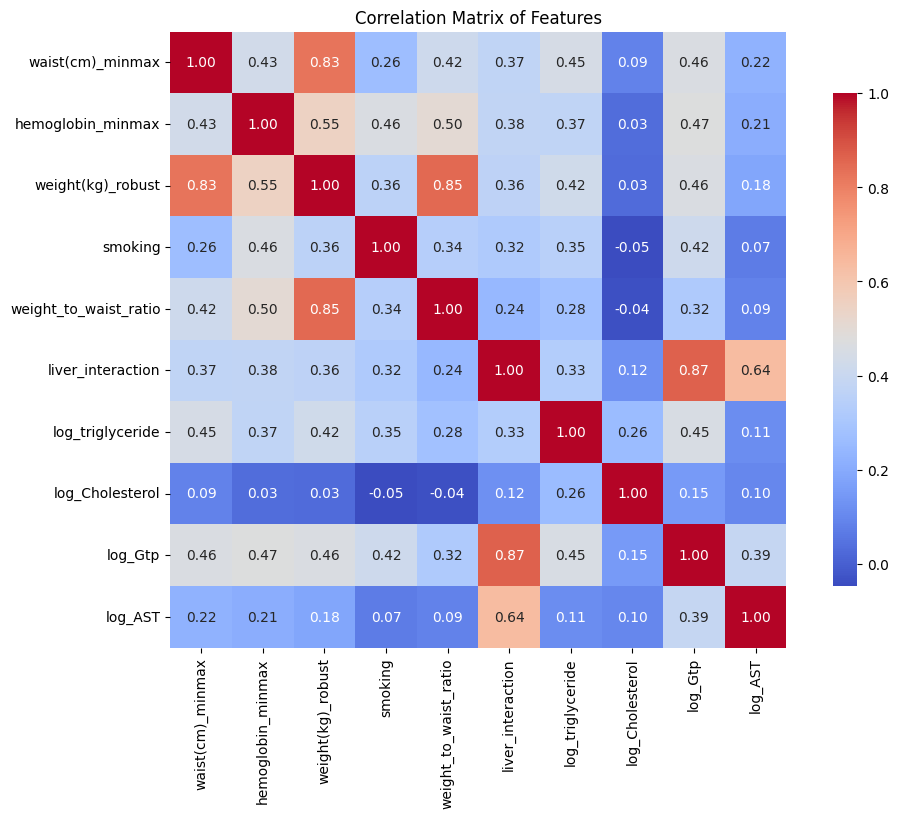

In [15]:

print("\nEngineering features")
df_engineered = engineer_features(df_scaled)

In [16]:
print("\nPreparing features")
    
selected_features = df_engineered.columns[df_engineered.columns != 'smoking'].tolist()
df_engineered.info()
X = df_engineered[selected_features]
y = df_engineered['smoking']


Preparing features
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 159256 entries, 0 to 159255
Data columns (total 10 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   waist(cm)_minmax       159256 non-null  float64
 1   hemoglobin_minmax      159256 non-null  float64
 2   weight(kg)_robust      159256 non-null  float64
 3   smoking                159256 non-null  int32  
 4   weight_to_waist_ratio  159256 non-null  float64
 5   liver_interaction      159256 non-null  float64
 6   log_triglyceride       159256 non-null  float64
 7   log_Cholesterol        159256 non-null  float64
 8   log_Gtp                159256 non-null  float64
 9   log_AST                159256 non-null  float64
dtypes: float64(9), int32(1)
memory usage: 11.5 MB


In [17]:
print("\nSplitting data")
X_train, X_val, X_test, y_train, y_val, y_test = split_data(X, y)


Splitting data
Data split completed!
Training set: 111479 (70.0%)
Validation set: 23888 (15.0%)
Test set: 23889 (15.0%)


In [18]:
print("\nTraining and evaluating models")
results = train_and_evaluate_models(
    X_train, X_val, X_test,
    y_train, y_val, y_test
)


Training and evaluating models

Training and evaluating random_forest

Performing Grid Search
Fitting 3 folds for each of 8 candidates, totalling 24 fits
[CV] END max_depth=10, min_samples_split=2, n_estimators=100; total time=  14.9s
[CV] END max_depth=10, min_samples_split=2, n_estimators=100; total time=  14.9s
[CV] END max_depth=10, min_samples_split=2, n_estimators=100; total time=  14.0s
[CV] END max_depth=10, min_samples_split=2, n_estimators=200; total time=  26.5s
[CV] END max_depth=10, min_samples_split=2, n_estimators=200; total time=  31.9s
[CV] END max_depth=10, min_samples_split=2, n_estimators=200; total time=  25.8s
[CV] END max_depth=10, min_samples_split=5, n_estimators=100; total time=  13.2s
[CV] END max_depth=10, min_samples_split=5, n_estimators=100; total time=  13.4s
[CV] END max_depth=10, min_samples_split=5, n_estimators=100; total time=  14.0s
[CV] END max_depth=10, min_samples_split=5, n_estimators=200; total time=  30.2s
[CV] END max_depth=10, min_samples_


Generating comparison plots


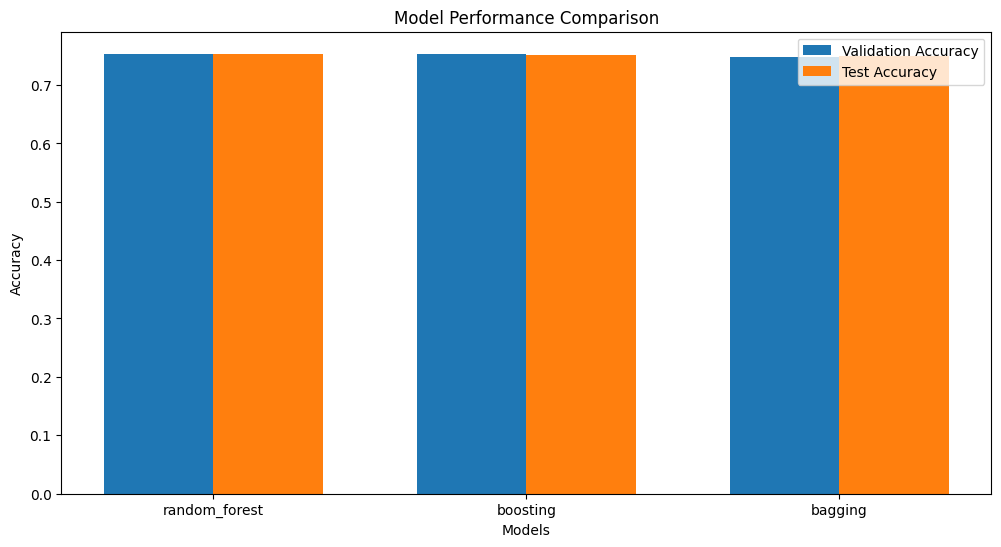

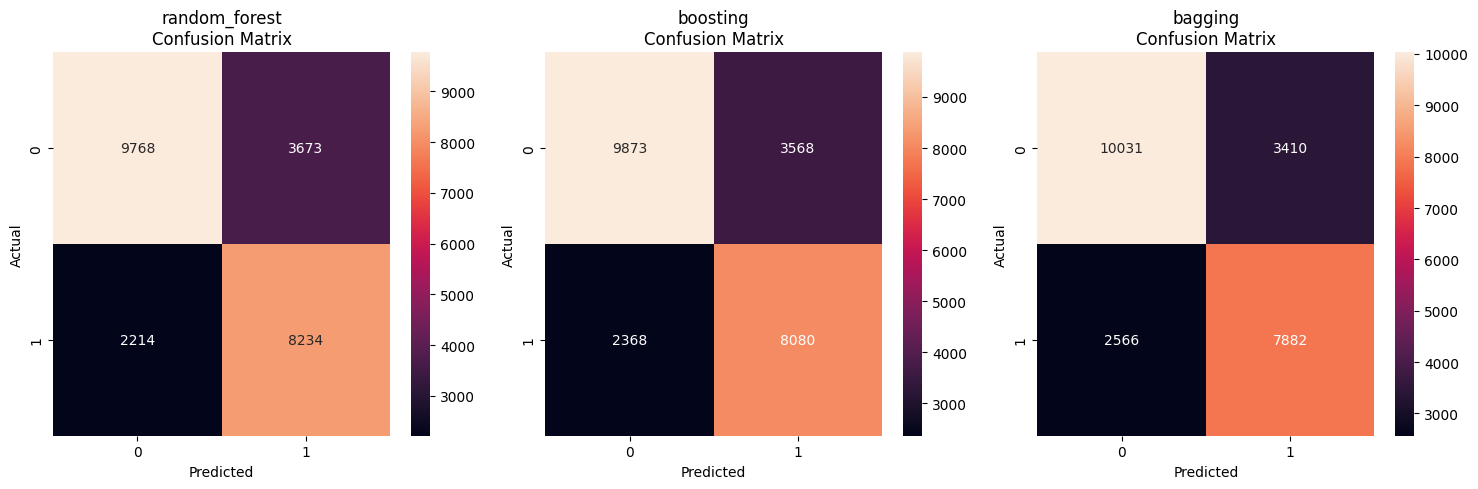

In [22]:
print("\nGenerating comparison plots")
plot_model_comparisons(results)

In [20]:
best_model_name = max(results.items(), 
                     key=lambda x: x[1]['test_scores']['accuracy'])[0]
    
print("\nFinal Results Summary:")
print(f"\nBest Model: {best_model_name}")
print(f"Best Model Test Scores:")
for metric, score in results[best_model_name]['test_scores'].items():
    print(f"{metric}: {score:.3f}")


Final Results Summary:

Best Model: random_forest
Best Model Test Scores:
accuracy: 0.754
roc_auc: 0.833
f1: 0.737
